### Predictive Analytics
#### Data Preprocessing for Modelling

In [2]:
# import essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [4]:
# load the dataset
data = pd.read_csv('data\diabetes_data_upload.csv')

# check the dimension of the dataset
print('Dimension of the dataset: ', data.shape)

# check the attributes in the dataset
print('Attributes in the dataset: ', data.columns.values)

# view the first 5 rows of the dataset
data.head()

Dimension of the dataset:  (520, 17)
Attributes in the dataset:  ['Age' 'Gender' 'Polyuria' 'Polydipsia' 'sudden weight loss' 'weakness'
 'Polyphagia' 'Genital thrush' 'visual blurring' 'Itching' 'Irritability'
 'delayed healing' 'partial paresis' 'muscle stiffness' 'Alopecia'
 'Obesity' 'class']


<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
C:\Users\shive\AppData\Local\Temp\ipykernel_29212\2571405158.py:2: SyntaxWarning: invalid escape sequence '\d'
  data = pd.read_csv('data\diabetes_data_upload.csv')


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes,Positive
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No,Positive
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No,Positive
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No,Positive
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Positive


In [5]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.2, random_state=122)

# dimension of train and test dataset
print('Dimension of training data: ', train.shape)
print('Dimension of test data: ', test.shape)

Dimension of training data:  (416, 17)
Dimension of test data:  (104, 17)


In [ ]:
# segregate the feature matrix and target vector from train and test data
Xtrain = train.drop(columns=['class'], axis=1)
ytrain = train['class']

Xtest = test.drop(columns=['class'], axis=1)
ytest = test['class']

In [ ]:
# encode the target/label for train and test dataset
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
ytrain_encoded = encoder.fit_transform(ytrain)
ytest_encoded = encoder.transform(ytest)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

# extracted the list of categorical columns to be encoded using OneHotEncoder
excluded_col = 'Age'
categorical_col = [col for col in Xtrain.columns if col != excluded_col]

# define the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first'), categorical_col)
    ],
    remainder='passthrough'  
)

# create the pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('scaler', MinMaxScaler())
])

# process the train and test data
Xtrain_transformed = pipeline.fit_transform(Xtrain)
Xtest_transformed = pipeline.transform(Xtest)

### Classification
#### Model 1 | Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# create a Decision Tree Classifier
tree = DecisionTreeClassifier(random_state=122)

# Define the hyperparameter grid
param_grid = {
    'criterion': ['gini', 'entropy'],
    'splitter': ['best', 'random'],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [2, 4]
}

# create the GridSearchCV object
grid_search_tree = GridSearchCV(tree, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# fit the grid search to the data
grid_search_tree.fit(Xtrain_transformed, ytrain_encoded)

# print the best parameters and the corresponding accuracy
print('Best Parameters: ', grid_search_tree.best_params_)
print('Best Accuracy: ', grid_search_tree.best_score_)

# get the best model
best_tree = grid_search_tree.best_estimator_

Best Parameters:  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'splitter': 'best'}
Best Accuracy:  0.935140562248996


#### Model 2 | Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

# create a logistic regression Classifier
logreg = LogisticRegression(random_state=122, max_iter=5000)

# define the hyperparameter grid
param_grid = {
    'penalty': ['l1', 'l2'],
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'saga']
}

# create the GridSearchCV object
grid_search_logreg = GridSearchCV(logreg, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# fit the grid search to the data
grid_search_logreg.fit(Xtrain_transformed, ytrain_encoded)

# print the best parameters and the corresponding accuracy
print('Best Parameters: ', grid_search_logreg.best_params_)
print('Best Accuracy: ', grid_search_logreg.best_score_)

# get the best model
best_logreg = grid_search_logreg.best_estimator_

Best Parameters:  {'C': 10, 'penalty': 'l1', 'solver': 'liblinear'}
Best Accuracy:  0.9255020080321286


#### Model 3 | Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# create a Random Forest Classifier
forest = RandomForestClassifier(random_state=122)

# define the hyperparameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'criterion': ['gini', 'entropy'],
    'max_depth': [10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [2, 4],
    'max_features': ['sqrt', 'log2']
}

# create the GridSearchCV object
grid_search_forest = GridSearchCV(forest, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# fit the grid search to the data
grid_search_forest.fit(Xtrain_transformed, ytrain_encoded)

# print the best parameters and the corresponding accuracy
print('Best Parameters: ', grid_search_forest.best_params_)
print('Best Accuracy: ', grid_search_forest.best_score_)

# get the best model
best_forest = grid_search_forest.best_estimator_

Best Parameters:  {'criterion': 'gini', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Best Accuracy:  0.9663224325874928


#### Model 4 | Naive Bayes

In [ ]:
from sklearn.naive_bayes import ComplementNB 

# create a Naive Bayes classifier
clf = ComplementNB()

# fit the classifier with training data
cNB = clf.fit(Xtrain_transformed,ytrain_encoded)

#### Model 5 | KNearestNeighbors

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# create the KNN classifier
knn = KNeighborsClassifier()

# define the parameter grid for hyperparameter tuning
param_grid = {
    'n_neighbors': np.arange(1, 21),  
    'p': [1, 2]  # 1 for Manhattan distance (L1), 2 for Euclidean distance (L2)
}

# create a GridSearchCV object with KNN and the parameter grid
grid_search_knn = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# fit the model with the training data
grid_search_knn.fit(Xtrain_transformed,ytrain_encoded)

# print the best parameters and the corresponding accuracy
print('Best Parameters: ', grid_search_knn.best_params_)
print('Best Accuracy: ', grid_search_knn.best_score_)

# get the best model
best_knn = grid_search_knn.best_estimator_

Best Parameters:  {'n_neighbors': 1, 'p': 1}
Best Accuracy:  0.971170395869191


#### Model 6 | Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC

# create the SVM classifier
svc = SVC(random_state=122)

# define the parameter grid for hyperparameter tuning
param_grid = {
    'C': [0.1, 1, 10, 100],                 # Regularization parameter
    'kernel': ['linear', 'rbf', 'poly'],    # Choice of kernel
    'gamma': ['scale', 'auto', 0.1, 1],     # Kernel coefficient for 'rbf' and 'poly'
    'degree': [2, 3, 4]                     # Degree of the polynomial kernel
}

# create a GridSearchCV object with SVM and the parameter grid
grid_search_svc = GridSearchCV(svc, param_grid, cv=5, scoring='accuracy')

# fit the model with the training data
grid_search_svc.fit(Xtrain_transformed,ytrain_encoded)

# print the best parameters and the corresponding accuracy
print('Best Parameters: ', grid_search_svc.best_params_)
print('Best Accuracy: ', grid_search_svc.best_score_)

# get the best model
best_svc = grid_search_svc.best_estimator_

Best Parameters:  {'C': 1, 'degree': 2, 'gamma': 1, 'kernel': 'rbf'}
Best Accuracy:  0.9687607573149742


### Performance Evaluation & Model Comparison

In [ ]:
# define a helper function to perform model evaluation based on key metrics
from sklearn.metrics import precision_recall_fscore_support, matthews_corrcoef

def performance_evaluation(X,y,clf,classifier_name=''):
    ypred = clf.predict(X)
    accuracy = clf.score(X,y)
    mcc = matthews_corrcoef(y, ypred)
    precision, recall, fscore, support = precision_recall_fscore_support(y, ypred, average='weighted', zero_division=0)
    metricName = ['Accuracy','Precision','Recall','F1_Score','MCC']
    metricValue = [accuracy,precision,recall,fscore,mcc]
    res = pd.DataFrame(metricValue, index=metricName, columns=[classifier_name])
    return res

In [ ]:
# generate the performance summary for various models trained
tree_summary = performance_evaluation(Xtest_transformed,ytest_encoded,best_tree,'Decision Tree')
logistic_summary = performance_evaluation(Xtest_transformed,ytest_encoded,best_logreg,'Logistic Regression')
forest_summary = performance_evaluation(Xtest_transformed,ytest_encoded,best_forest,'Random Forest')
naivebayes_summary = performance_evaluation(Xtest_transformed,ytest_encoded,cNB,'Naive Bayes')
knn_summary = performance_evaluation(Xtest_transformed,ytest_encoded,best_knn,'K Nearest Neigbors')
svc_summary = performance_evaluation(Xtest_transformed,ytest_encoded,best_svc,'Support Vector Machine')

# combine the summary of each model into a dataframe 
comparison_df = pd.concat([tree_summary,forest_summary,logistic_summary,naivebayes_summary,knn_summary,svc_summary], axis=1)

# disply the summary dafaframe
display(comparison_df)

,Decision Tree,Random Forest,Logistic Regression,Naive Bayes,K Nearest Neigbors,Support Vector Machine
Accuracy,0.942308,0.942308,0.875000,0.913462,0.961538,0.942308
Precision,0.944138,0.947324,0.878676,0.915740,0.961933,0.947324
Recall,0.942308,0.942308,0.875000,0.913462,0.961538,0.942308
F1_Score,0.941716,0.941342,0.872456,0.912303,0.961358,0.941342
MCC,0.880075,0.882852,0.738075,0.819218,0.919540,0.882852


##### Notes: 

The Matthews Correlation Coefficient (MCC) is a metric commonly used to assess the performance of binary classification models. It takes into account true positives, true negatives, false positives, and false negatives and provides a balanced measure, especially when the classes are imbalanced.


Here's why MCC is a useful metric:

1. **Balancing Act:** MCC takes into account all four elements of the confusion matrix, making it suitable for imbalanced datasets. This is crucial when the number of instances in one class is much higher than the other, as accuracy alone can be misleading.

2. **Range of Values:** MCC ranges from -1 to 1. A score of 1 indicates a perfect prediction, 0 means no better than random, and -1 indicates total disagreement between prediction and observation. This range provides a clear understanding of the quality of the model.

3. **Symmetry:** MCC is symmetric; it considers errors in both positive and negative classes. This is especially important when the costs of false positives and false negatives are different.

4. **Effectiveness in Binary Classification:** MCC is particularly effective for binary classification problems and is less sensitive to class imbalance compared to some other metrics like accuracy.

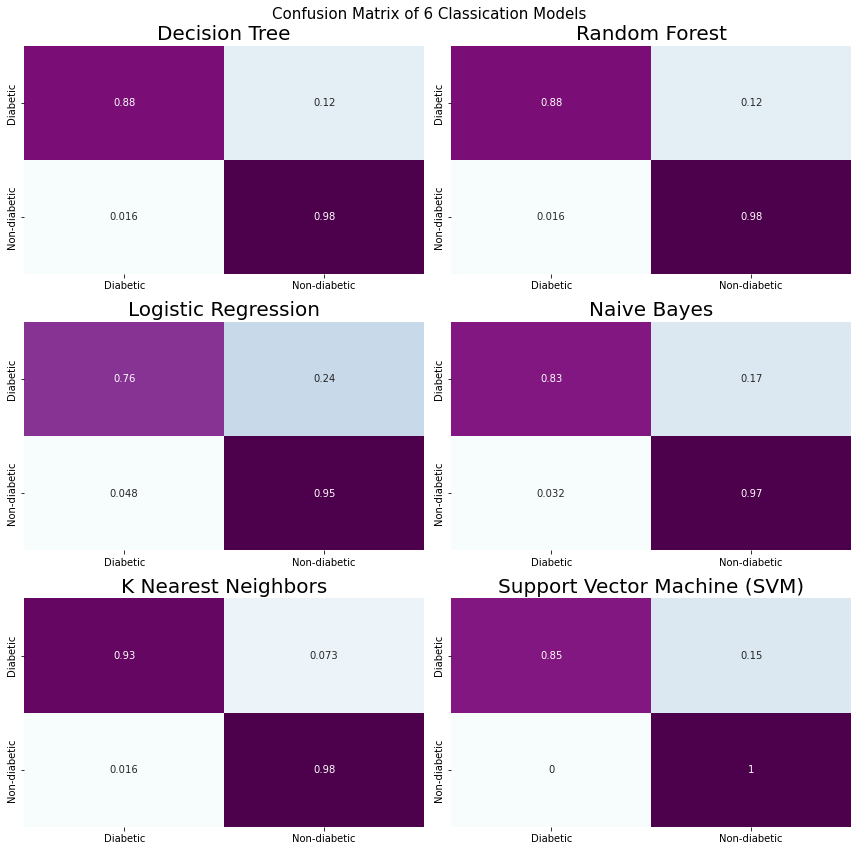

In [ ]:
# visualize the confusion matrix using a heatmap
from sklearn.metrics import confusion_matrix

labels = ['Diabetic', 'Non-diabetic']

ypred_tree = best_tree.predict(Xtest_transformed)
cm_tree = confusion_matrix(ytest_encoded, ypred_tree, normalize='true')

ypred_forest = best_forest.predict(Xtest_transformed)
cm_forest = confusion_matrix(ytest_encoded, ypred_tree, normalize='true')

ypred_logistic = best_logreg.predict(Xtest_transformed)
cm_logistic = confusion_matrix(ytest_encoded, ypred_logistic, normalize='true')

ypred_nb = cNB.predict(Xtest_transformed)
cm_nb = confusion_matrix(ytest_encoded, ypred_nb, normalize='true')

ypred_knn = best_knn.predict(Xtest_transformed)
cm_knn = confusion_matrix(ytest_encoded, ypred_knn, normalize='true')

ypred_svc = best_svc.predict(Xtest_transformed)
cm_svc = confusion_matrix(ytest_encoded, ypred_svc, normalize='true')


# confusion matrix for 6 classification models
figure, axes = plt.subplots(3,2, figsize=(12,12))
sns.heatmap(cm_tree, annot=True, cmap='BuPu', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[0,0])
axes[0,0].set_title('Decision Tree', fontsize=20)
sns.heatmap(cm_forest, annot=True, cmap='BuPu', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[0,1])
axes[0,1].set_title('Random Forest', fontsize=20)
sns.heatmap(cm_logistic, annot=True, cmap='BuPu', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[1,0])
axes[1,0].set_title('Logistic Regression', fontsize=20)
sns.heatmap(cm_nb, annot=True, cmap='BuPu', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[1,1])
axes[1,1].set_title('Naive Bayes', fontsize=20)
sns.heatmap(cm_knn, annot=True, cmap='BuPu', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[2,0])
axes[2,0].set_title('K Nearest Neighbors', fontsize=20)
sns.heatmap(cm_svc, annot=True, cmap='BuPu', xticklabels=labels, yticklabels=labels, cbar=False, ax=axes[2,1])
axes[2,1].set_title('Support Vector Machine (SVM)', fontsize=20)

figure.suptitle('Confusion Matrix of 6 Classication Models', fontsize=15)
plt.tight_layout(pad=1)
plt.show()